# Fashion-MNIST ile Kıyafet Görüntülerinin CNN ile Sınıflandırılması

**Problem:** Bir e-ticaret / ikinci el platformuna yüklenen ürün fotoğraflarına otomatik kategori önermek. Girdi 28×28 gri tonlamalı bir ürün görüntüsü, çıktı 10 kategoriden biri.
Model emin olmadığı görüntüleri insan kontrolüne bırakabilmelidir; bu yüzden doğruluğun yanında **tahmin güveni** de incelenir.

**Veri seti:** Fashion-MNIST — Zalando Research · https://github.com/zalandoresearch/fashion-mnist (MIT lisansı)

> Colab'da: *Çalışma zamanı → Tümünü çalıştır*. Veri seti `tf.keras.datasets` ile otomatik indirilir. CPU'da CNN eğitimi yaklaşık 20–30 dakika, GPU'da birkaç dakika sürer (*Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU*).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__)

SINIFLAR = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
            "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
SINIFLAR_TR = ["Tişört/üst", "Pantolon", "Kazak", "Elbise", "Mont",
               "Sandalet", "Gömlek", "Spor ayakkabı", "Çanta", "Bot"]

I0000 00:00:1792313511.112598     389 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792313512.435070     389 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Veri setinin tanıtılması

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
print("Eğitim:", x_train_full.shape, y_train_full.shape)
print("Test  :", x_test.shape, y_test.shape)
print("Piksel aralığı:", x_train_full.min(), "-", x_train_full.max(), "| veri tipi:", x_train_full.dtype)

dagilim = pd.DataFrame({
    "Sınıf": [f"{i} · {SINIFLAR[i]} ({SINIFLAR_TR[i]})" for i in range(10)],
    "Eğitim": np.bincount(y_train_full),
    "Test": np.bincount(y_test),
})
dagilim

Eğitim: (60000, 28, 28) (60000,)
Test  : (10000, 28, 28) (10000,)
Piksel aralığı: 0 - 255 | veri tipi: uint8


,Sınıf,Eğitim,Test
0,0 · T-shirt/top (Tişört/üst),6000,1000
1,1 · Trouser (Pantolon),6000,1000
2,2 · Pullover (Kazak),6000,1000
3,3 · Dress (Elbise),6000,1000
4,4 · Coat (Mont),6000,1000
5,5 · Sandal (Sandalet),6000,1000
6,6 · Shirt (Gömlek),6000,1000
7,7 · Sneaker (Spor ayakkabı),6000,1000
8,8 · Bag (Çanta),6000,1000
9,9 · Ankle boot (Bot),6000,1000


Her sınıfta eğitimde 6.000, testte 1.000 görüntü var: **sınıf dengesizliği yok**. Bu yüzden accuracy yanıltıcı değildir; yine de sınıf bazında precision/recall da raporlanacak.

## 2. Veri keşfi

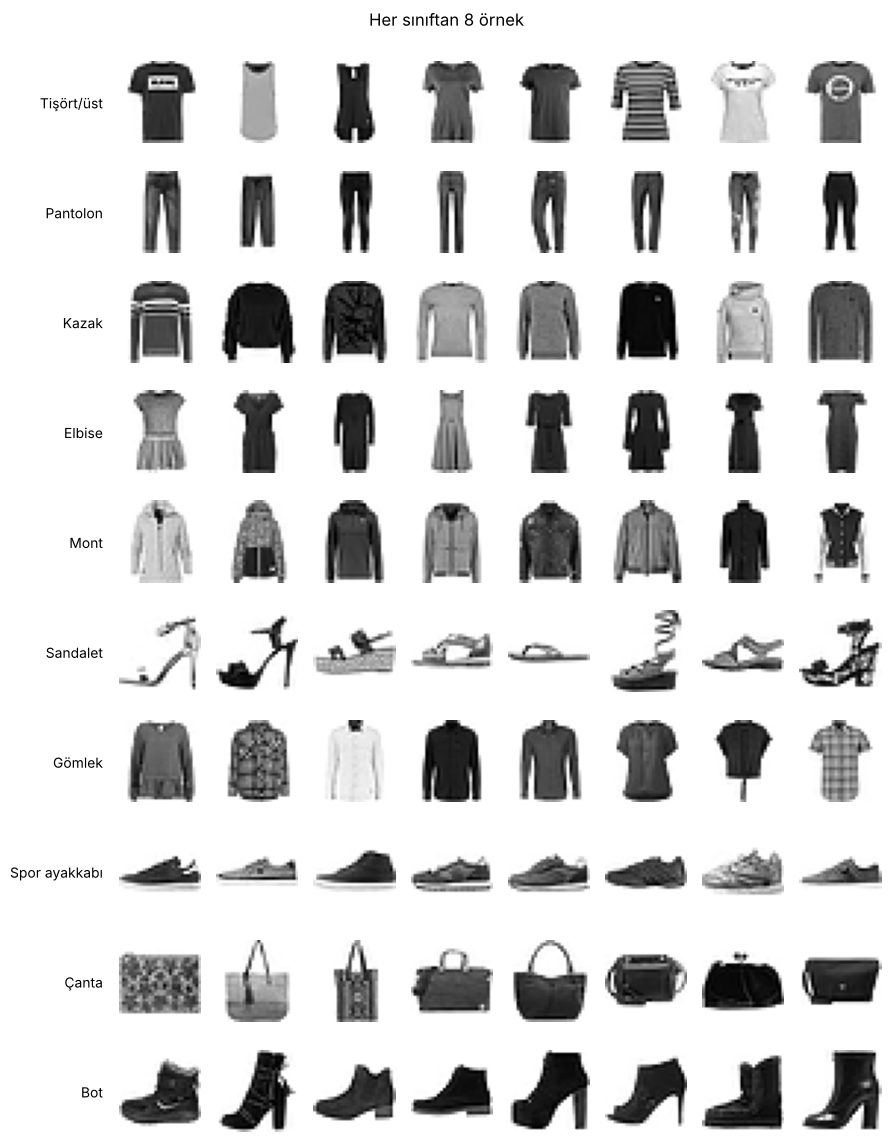

In [3]:
# Görsel 1: her sınıftan örnek görüntüler
fig, axes = plt.subplots(10, 8, figsize=(9, 11.5))
for c in range(10):
    idx = np.where(y_train_full == c)[0][:8]
    for j, i in enumerate(idx):
        ax = axes[c, j]; ax.imshow(x_train_full[i], cmap="gray_r"); ax.axis("off")
    axes[c, 0].text(-6, 14, SINIFLAR_TR[c], ha="right", va="center", fontsize=10)
plt.suptitle("Her sınıftan 8 örnek", y=0.995)
plt.tight_layout(); plt.savefig("g1_ornekler.png", dpi=130, bbox_inches="tight"); plt.show()

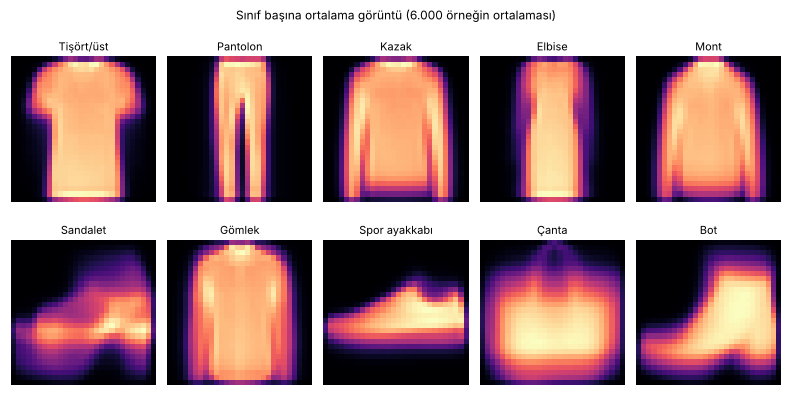

In [4]:
# Görsel 2: sınıf başına ortalama görüntü — sınıflar arası benzerliği gösterir
fig, axes = plt.subplots(2, 5, figsize=(11, 5.8))
ortalama = np.stack([x_train_full[y_train_full == c].mean(axis=0) for c in range(10)])
for c, ax in enumerate(axes.flat):
    ax.imshow(ortalama[c], cmap="magma"); ax.set_title(SINIFLAR_TR[c], fontsize=11); ax.axis("off")
plt.suptitle("Sınıf başına ortalama görüntü (6.000 örneğin ortalaması)")
plt.tight_layout(h_pad=2.0); plt.savefig("g2_ortalama.png", dpi=130, bbox_inches="tight"); plt.show()

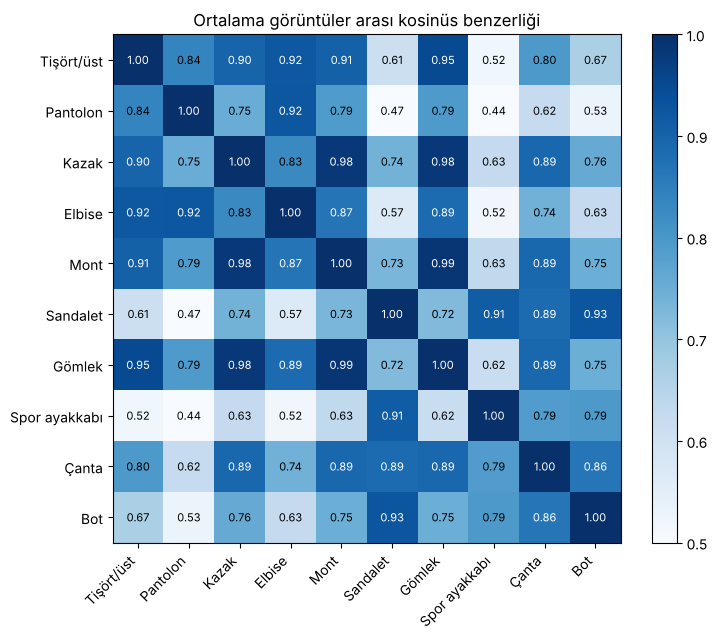

En benzer 5 sınıf çifti:
  Mont – Gömlek: 0.987
  Kazak – Mont: 0.984
  Kazak – Gömlek: 0.983
  Tişört/üst – Gömlek: 0.949
  Sandalet – Bot: 0.927


In [5]:
# Görsel 3: ortalama görüntüler arasındaki benzerlik (kosinüs) — hangi sınıflar karışabilir?
v = ortalama.reshape(10, -1); v = v / np.linalg.norm(v, axis=1, keepdims=True)
benzerlik = v @ v.T
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(benzerlik, cmap="Blues", vmin=0.5, vmax=1)
ax.set_xticks(range(10), SINIFLAR_TR, rotation=45, ha="right"); ax.set_yticks(range(10), SINIFLAR_TR)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{benzerlik[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if benzerlik[i, j] > 0.85 else "black")
plt.colorbar(im, fraction=0.046); ax.set_title("Ortalama görüntüler arası kosinüs benzerliği")
plt.tight_layout(); plt.savefig("g3_benzerlik.png", dpi=130, bbox_inches="tight"); plt.show()

ust = [(benzerlik[i, j], SINIFLAR_TR[i], SINIFLAR_TR[j]) for i in range(10) for j in range(i + 1, 10)]
print("En benzer 5 sınıf çifti:")
for s, a, b in sorted(ust, reverse=True)[:5]:
    print(f"  {a} – {b}: {s:.3f}")

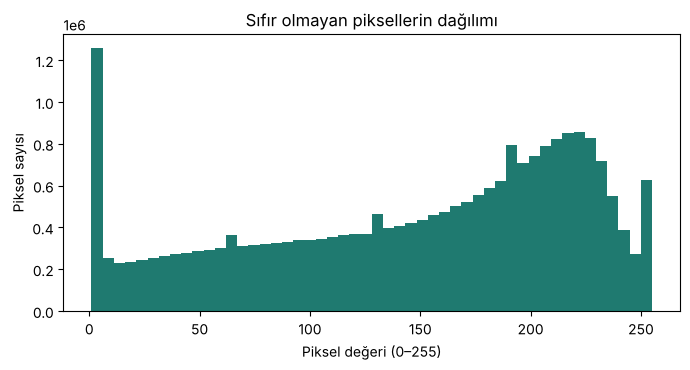

Arka plan (0) piksel oranı: 50.2%


In [6]:
# Görsel 4: piksel yoğunluğu dağılımı (sıfır olmayan pikseller)
plt.figure(figsize=(7, 3.8))
plt.hist(x_train_full[x_train_full > 0].ravel(), bins=50, color="#1F7A70")
plt.xlabel("Piksel değeri (0–255)"); plt.ylabel("Piksel sayısı")
plt.title("Sıfır olmayan piksellerin dağılımı")
plt.tight_layout(); plt.savefig("g4_piksel.png", dpi=130, bbox_inches="tight"); plt.show()
print(f"Arka plan (0) piksel oranı: {(x_train_full == 0).mean():.1%}")

## 3. Veri ön işleme

In [7]:
# 1) Normalizasyon: 0–255 → 0–1   2) Kanal boyutu ekleme: (28,28) → (28,28,1)
x_train_full_n = (x_train_full / 255.0).astype("float32")[..., None]
x_test_n = (x_test / 255.0).astype("float32")[..., None]

# 3) Eğitim/doğrulama ayrımı: 54.000 / 6.000, sınıf oranı korunarak (stratify)
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train_full_n, y_train_full, test_size=6000, stratify=y_train_full, random_state=SEED)
print("Eğitim:", x_tr.shape, "| Doğrulama:", x_val.shape, "| Test:", x_test_n.shape)
print("Eksik değer:", int(np.isnan(x_tr).sum()))

Eğitim: (54000, 28, 28, 1) | Doğrulama: (6000, 28, 28, 1) | Test: (10000, 28, 28, 1)
Eksik değer: 0


- Eksik değer yok; görüntü boyutları sabit (28×28) olduğu için yeniden boyutlandırma gerekmedi.
- Etiketler 0–9 tamsayı olarak bırakıldı (`sparse_categorical_crossentropy` ile one-hot gerekmez).
- **Veri artırma** (yalnızca eğitim sırasında, modelin ilk katmanlarında): ±%8 kaydırma ve yatay çevirme. Kıyafetler yatayda simetrik olduğu için çevirme etiketi değiştirmez; dikey çevirme kullanılmadı.

## 4. Temel model (baseline): tam bağlantılı ağ (MLP)

In [8]:
mlp = models.Sequential([
    layers.Input((28, 28, 1)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
], name="MLP_baseline")
mlp.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
gecmis_mlp = mlp.fit(x_tr, y_tr, validation_data=(x_val, y_val), epochs=15, batch_size=128, verbose=2,
                     callbacks=[callbacks.EarlyStopping(patience=3, restore_best_weights=True)])

Epoch 1/15


422/422 - 2s - 5ms/step - accuracy: 0.7910 - loss: 0.5935 - val_accuracy: 0.8475 - val_loss: 0.4224


Epoch 2/15


422/422 - 1s - 3ms/step - accuracy: 0.8474 - loss: 0.4256 - val_accuracy: 0.8707 - val_loss: 0.3573


Epoch 3/15


...

422/422 - 2s - 4ms/step - accuracy: 0.8995 - loss: 0.2696 - val_accuracy: 0.8968 - val_loss: 0.2774


Epoch 14/15


422/422 - 2s - 6ms/step - accuracy: 0.8993 - loss: 0.2661 - val_accuracy: 0.8952 - val_loss: 0.2848


Epoch 15/15


422/422 - 3s - 6ms/step - accuracy: 0.9026 - loss: 0.2588 - val_accuracy: 0.8937 - val_loss: 0.2798


## 5. CNN modeli

In [9]:
artirma = models.Sequential([
    layers.RandomTranslation(0.08, 0.08, fill_mode="constant"),
    layers.RandomFlip("horizontal"),
], name="veri_artirma")

def conv_blok(filtre):
    return [layers.Conv2D(filtre, 3, padding="same", use_bias=False), layers.BatchNormalization(), layers.ReLU()]

cnn = models.Sequential([
    layers.Input((28, 28, 1)),
    artirma,
    *conv_blok(32), *conv_blok(32), layers.MaxPooling2D(), layers.Dropout(0.25),   # 28×28 → 14×14
    *conv_blok(64), *conv_blok(64), layers.MaxPooling2D(), layers.Dropout(0.25),   # 14×14 → 7×7
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
], name="CNN")
cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ veri_artirma (Sequential)       │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,394 (1.79 MB)

 Trainable params: 468,010 (1.79 MB)

 Non-trainable params: 384 (1.50 KB)

**Tasarım gerekçesi**
- **Conv2D (3×3)** katmanları kenar, doku ve kol/yaka gibi yerel şekilleri öğrenir; iki blokta filtre sayısı 32 → 64 artar.
- **BatchNormalization** eğitimi kararlı ve hızlı yapar; **MaxPooling** boyutu yarıya indirir.
- **Dropout** (0,25 / 0,5) ve **veri artırma** ezberlemeyi azaltır.
- Çıkış: 10 nöron + **softmax** (10 sınıf olasılığı). Loss: **sparse categorical crossentropy**. Optimizer: **Adam** (lr = 0,001).

## 6. CNN eğitimi

In [10]:
cb = [
    callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
]
gecmis = cnn.fit(x_tr, y_tr, validation_data=(x_val, y_val),
                 epochs=20, batch_size=128, callbacks=cb, verbose=2)
print("Eğitilen epoch:", len(gecmis.history["loss"]))

Epoch 1/20


422/422 - 55s - 130ms/step - accuracy: 0.6097 - loss: 1.0348 - val_accuracy: 0.5523 - val_loss: 1.1623 - learning_rate: 0.0010


Epoch 2/20


422/422 - 55s - 131ms/step - accuracy: 0.7207 - loss: 0.7216 - val_accuracy: 0.8215 - val_loss: 0.4406 - learning_rate: 0.0010


Epoch 3/20


...

Epoch 19/20


422/422 - 53s - 125ms/step - accuracy: 0.8782 - loss: 0.3342 - val_accuracy: 0.9270 - val_loss: 0.2023 - learning_rate: 5.0000e-04


Epoch 20/20


422/422 - 53s - 125ms/step - accuracy: 0.8810 - loss: 0.3295 - val_accuracy: 0.9273 - val_loss: 0.2080 - learning_rate: 5.0000e-04


Eğitilen epoch: 20


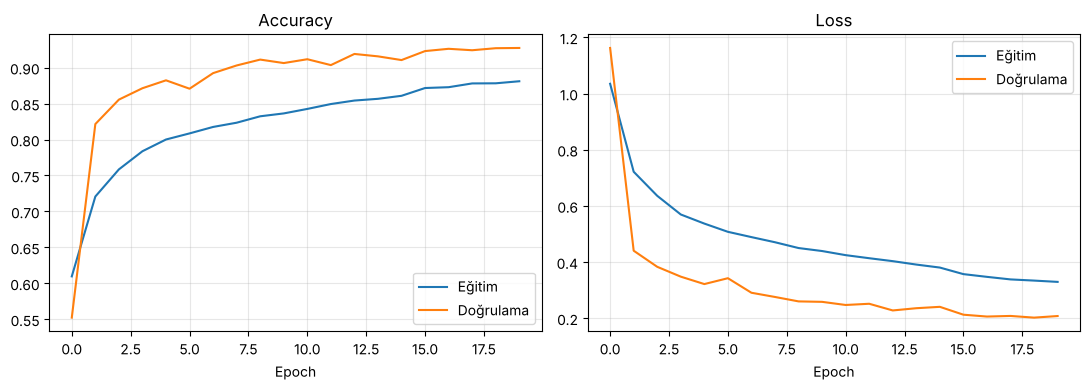

In [11]:
# Görsel 5: eğitim ve doğrulama eğrileri
h = gecmis.history
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(h["accuracy"], label="Eğitim"); axes[0].plot(h["val_accuracy"], label="Doğrulama")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(h["loss"], label="Eğitim"); axes[1].plot(h["val_loss"], label="Doğrulama")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("g5_egitim.png", dpi=130, bbox_inches="tight"); plt.show()

Not: Eğitim accuracy'si doğrulamadan düşük görünebilir; çünkü eğitimde dropout ve veri artırma açıktır, doğrulamada kapalıdır.

## 7. Test değerlendirmesi

In [12]:
def metrikler(model, ad):
    olas = model.predict(x_test_n, verbose=0)
    tahmin = olas.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_test, tahmin, average="macro")
    return olas, tahmin, {"Model": ad, "Parametre": model.count_params(),
                          "Accuracy": accuracy_score(y_test, tahmin),
                          "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f}

olas_mlp, tahmin_mlp, s_mlp = metrikler(mlp, "MLP (baseline)")
olas_cnn, tahmin_cnn, s_cnn = metrikler(cnn, "CNN")
sonuc = pd.DataFrame([s_mlp, s_cnn]).set_index("Model")
sonuc.round(4)

,Parametre,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,,
MLP (baseline),203530,0.8851,0.8856,0.8851,0.8851
CNN,468394,0.9186,0.9180,0.9186,0.9181


In [13]:
print(classification_report(y_test, tahmin_cnn, target_names=SINIFLAR_TR, digits=3))
rapor = pd.DataFrame(classification_report(y_test, tahmin_cnn, target_names=SINIFLAR_TR, output_dict=True)).T

               precision    recall  f1-score   support

   Tişört/üst      0.846     0.893     0.869      1000
     Pantolon      0.987     0.986     0.986      1000
        Kazak      0.896     0.894     0.895      1000
       Elbise      0.912     0.927     0.919      1000
         Mont      0.869     0.878     0.874      1000
     Sandalet      0.986     0.977     0.981      1000
       Gömlek      0.780     0.717     0.747      1000
Spor ayakkabı      0.947     0.966     0.956      1000
        Çanta      0.989     0.991     0.990      1000
          Bot      0.968     0.957     0.962      1000

     accuracy                          0.919     10000
    macro avg      0.918     0.919     0.918     10000
 weighted avg      0.918     0.919     0.918     10000



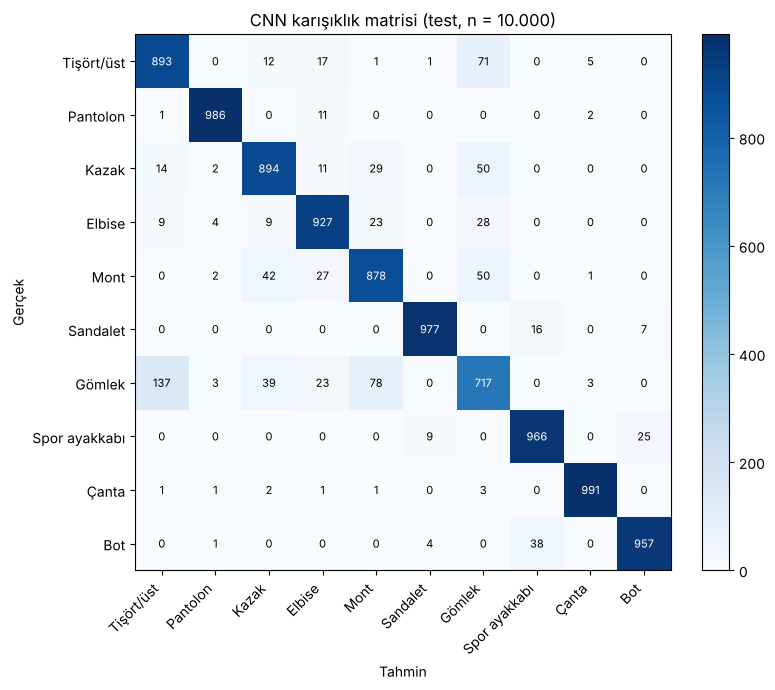

In [14]:
# Görsel 6: karışıklık matrisi (CNN, satır = gerçek sınıf)
cm = confusion_matrix(y_test, tahmin_cnn)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10), SINIFLAR_TR, rotation=45, ha="right"); ax.set_yticks(range(10), SINIFLAR_TR)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Tahmin"); ax.set_ylabel("Gerçek"); ax.set_title("CNN karışıklık matrisi (test, n = 10.000)")
plt.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.savefig("g6_confusion.png", dpi=130, bbox_inches="tight"); plt.show()

## 8. Hata analizi

In [15]:
# En çok karıştırılan sınıf çiftleri
hatalar = [(cm[i, j], SINIFLAR_TR[i], SINIFLAR_TR[j]) for i in range(10) for j in range(10) if i != j]
karisan = pd.DataFrame(sorted(hatalar, reverse=True)[:6], columns=["Adet", "Gerçek", "Tahmin"])
print("Toplam hatalı tahmin:", int((tahmin_cnn != y_test).sum()))
karisan

Toplam hatalı tahmin: 814


,Adet,Gerçek,Tahmin
0,137,Gömlek,Tişört/üst
1,78,Gömlek,Mont
2,71,Tişört/üst,Gömlek
3,50,Mont,Gömlek
4,50,Kazak,Gömlek
5,42,Mont,Kazak


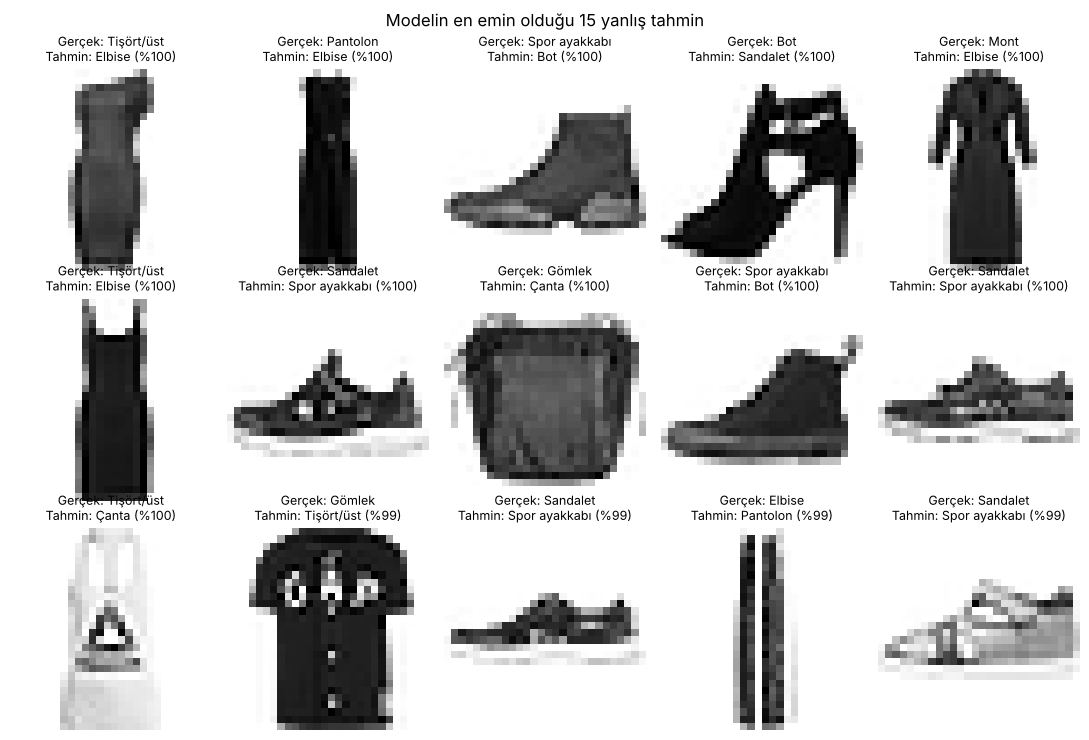

In [16]:
# Görsel 7: en emin olunan yanlış tahminler
yanlis = np.where(tahmin_cnn != y_test)[0]
guven = olas_cnn.max(1)
sec = yanlis[np.argsort(-guven[yanlis])][:15]
fig, axes = plt.subplots(3, 5, figsize=(11, 7.5))
for ax, i in zip(axes.flat, sec):
    ax.imshow(x_test[i], cmap="gray_r"); ax.axis("off")
    ax.set_title(f"Gerçek: {SINIFLAR_TR[y_test[i]]}\nTahmin: {SINIFLAR_TR[tahmin_cnn[i]]} (%{guven[i]*100:.0f})", fontsize=9)
plt.suptitle("Modelin en emin olduğu 15 yanlış tahmin")
plt.tight_layout(); plt.savefig("g7_yanlislar.png", dpi=130, bbox_inches="tight"); plt.show()

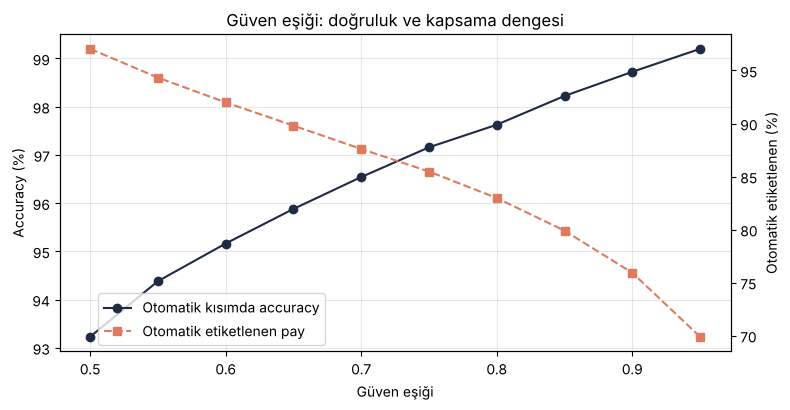

,Eşik,Otomatik etiketlenen (%),Otomatik kısımda accuracy (%)
0,0.50,97.04,93.23
1,0.55,94.33,94.38
2,0.60,91.99,95.16
3,0.65,89.80,95.88
4,0.70,87.60,96.54
5,0.75,85.47,97.16
6,0.80,82.97,97.63
7,0.85,79.89,98.22
8,0.90,75.92,98.72
9,0.95,69.89,99.20


In [17]:
# Görsel 8: güven eşiği analizi — düşük güvenli tahminleri insan kontrolüne gönderirsek
esikler = np.round(np.arange(0.50, 1.00, 0.05), 2)
satirlar = []
for e in esikler:
    oto = guven >= e
    satirlar.append({"Eşik": e, "Otomatik etiketlenen (%)": oto.mean() * 100,
                     "Otomatik kısımda accuracy (%)": (tahmin_cnn[oto] == y_test[oto]).mean() * 100})
esik_tablo = pd.DataFrame(satirlar)

fig, ax1 = plt.subplots(figsize=(8, 4.2))
ax1.plot(esik_tablo["Eşik"], esik_tablo["Otomatik kısımda accuracy (%)"], "o-", color="#1F2A44", label="Otomatik kısımda accuracy")
ax1.set_ylabel("Accuracy (%)"); ax1.set_xlabel("Güven eşiği")
ax2 = ax1.twinx()
ax2.plot(esik_tablo["Eşik"], esik_tablo["Otomatik etiketlenen (%)"], "s--", color="#E07A5F", label="Otomatik etiketlenen pay")
ax2.set_ylabel("Otomatik etiketlenen (%)")
fig.legend(loc="lower left", bbox_to_anchor=(0.12, 0.15)); ax1.grid(alpha=.3)
plt.title("Güven eşiği: doğruluk ve kapsama dengesi")
plt.tight_layout(); plt.savefig("g8_esik.png", dpi=130, bbox_inches="tight"); plt.show()
esik_tablo.round(2)

## 9. Kısa özet

In [18]:
print(f"CNN test accuracy : {s_cnn['Accuracy']:.4f}  | macro F1: {s_cnn['F1 (macro)']:.4f}")
print(f"MLP test accuracy : {s_mlp['Accuracy']:.4f}  | macro F1: {s_mlp['F1 (macro)']:.4f}")
en_zayif = rapor.loc[SINIFLAR_TR, "f1-score"].sort_values().head(3)
print("En düşük F1 alan sınıflar:"); print(en_zayif.round(3))
r90 = esik_tablo.loc[esik_tablo["Eşik"] == 0.9].iloc[0]
print(f"Eşik 0,90: görüntülerin %{r90['Otomatik etiketlenen (%)']:.1f}'i otomatik, bu kısımda accuracy %{r90['Otomatik kısımda accuracy (%)']:.2f}")

CNN test accuracy : 0.9186  | macro F1: 0.9181
MLP test accuracy : 0.8851  | macro F1: 0.8851
En düşük F1 alan sınıflar:
Gömlek        0.747
Tişört/üst    0.869
Mont          0.874
Name: f1-score, dtype: float64
Eşik 0,90: görüntülerin %75.9'i otomatik, bu kısımda accuracy %98.72
